In [2]:
import sys

print("Python version:")
print(sys.version)

print("\nPython executable:")
print(sys.executable)

Python version:
3.11.9 | packaged by conda-forge | (main, Apr 19 2024, 18:27:10) [MSC v.1938 64 bit (AMD64)]

Python executable:
d:\DoAnHocMay\Crop_recommendation\.venv\Scripts\python.exe


# EDA và Trực quan hóa dữ liệu
## Đề tài: Gợi ý loại cây trồng phù hợp dựa trên đặc tính đất và khí hậu

**Dataset:** Crop Recommendation Dataset

**Vai trò:** Thành viên 2 - Data Analyst

### Mục tiêu
- Khám phá và hiểu cấu trúc của bộ dữ liệu.
- Kiểm tra chất lượng dữ liệu.
- Phân tích các đặc trưng về đất và khí hậu.
- Kiểm tra dữ liệu thiếu và dữ liệu trùng lặp.
- Phát hiện các giá trị dị thường (Outliers).
- Phân tích mối tương quan giữa các biến.
- Trực quan hóa dữ liệu bằng biểu đồ.
- Đưa ra các nhận xét phục vụ bước tiền xử lý và xây dựng mô hình.

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Các thư viện đã được import thành công!")

Các thư viện đã được import thành công!


## 1. Đọc dữ liệu

Bộ dữ liệu Crop Recommendation chứa các thông tin về đặc tính đất và điều kiện khí hậu, được sử dụng để dự đoán loại cây trồng phù hợp.

Các đặc trưng chính gồm:
- N: Hàm lượng Nitơ trong đất.
- P: Hàm lượng Photpho trong đất.
- K: Hàm lượng Kali trong đất.
- temperature: Nhiệt độ.
- humidity: Độ ẩm.
- ph: Độ pH của đất.
- rainfall: Lượng mưa.
- label: Loại cây trồng cần dự đoán.

In [40]:
data_path = "../data/raw/Crop_recommendation.csv"

df = pd.read_csv(data_path)

print("Đọc dataset thành công!")
print("Kích thước dataset:", df.shape)

Đọc dataset thành công!
Kích thước dataset: (2200, 8)


In [26]:
print("Kiểu dữ liệu của df:", type(df))
print("Kích thước dataset:", df.shape)

Kiểu dữ liệu của df: <class 'pandas.DataFrame'>
Kích thước dataset: (2200, 8)


## 2. Khám phá dữ liệu ban đầu

Trước tiên, sử dụng `head()` để quan sát một số dòng đầu tiên của dataset và kiểm tra tên các cột cũng như giá trị của từng biến.

In [44]:
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])

Số dòng: 2200
Số cột: 8


In [28]:
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## 3. Thông tin tổng quan về dataset

Dataset gồm 2.200 dòng dữ liệu và 8 thuộc tính. Trong đó có 7 biến đầu vào gồm N, P, K, temperature, humidity, ph và rainfall; biến `label` là nhãn mục tiêu đại diện cho loại cây trồng cần dự đoán.

Các biến N, P, K có kiểu dữ liệu số nguyên (`int64`), trong khi temperature, humidity, ph và rainfall có kiểu số thực (`float64`). Biến `label` có kiểu chuỗi (`str`). Đặc biệt, tất cả 8 cột đều có 2.200 giá trị không bị thiếu, cho thấy dataset không có missing values tại bước kiểm tra ban đầu.

In [43]:
df.tail()

,N,P,K,temperature,humidity,ph,rainfall,label
2195,107,34,32,26.774637,66.413269,6.780064,177.774507,coffee
2196,99,15,27,27.417112,56.636362,6.086922,127.924610,coffee
2197,118,33,30,24.131797,67.225123,6.362608,173.322839,coffee
2198,117,32,34,26.272418,52.127394,6.758793,127.175293,coffee
2199,104,18,30,23.603016,60.396475,6.779833,140.937041,coffee


## Kiểm tra những dòng cuối của dataset

In [67]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB


### Nhận xét

Các đặc trưng trong dataset có phạm vi giá trị khác nhau. N, P và K có mức độ biến thiên tương đối lớn, trong khi nhiệt độ, độ ẩm và pH có khoảng giá trị tập trung hơn. Lượng mưa có phạm vi biến động khá rộng, từ khoảng 20 đến gần 299.

In [66]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


### Nhận xét

Dataset không có giá trị bị thiếu (missing values). Vì vậy, ở bước EDA hiện tại không cần thực hiện xử lý hoặc thay thế dữ liệu thiếu.

### Nhận xét

Kết quả kiểm tra cho thấy tất cả các cột đều có 0 giá trị thiếu. Như vậy, dataset không chứa missing values và chưa cần thực hiện các phương pháp xử lý dữ liệu thiếu ở bước tiền xử lý.

In [65]:
missing_values = df.isnull().sum()

print("Số lượng giá trị thiếu ở từng cột:")
print(missing_values)

Số lượng giá trị thiếu ở từng cột:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64


### Nhận xét

Dataset không có dòng dữ liệu trùng lặp. Điều này cho thấy mỗi mẫu dữ liệu trong tập hiện tại là một bản ghi riêng biệt và chưa cần loại bỏ dữ liệu duplicate.

In [64]:
duplicate_count = df.duplicated().sum()

print("Số dòng dữ liệu trùng lặp:", duplicate_count)

Số dòng dữ liệu trùng lặp: 0


In [63]:
numeric_features = [
    "N",
    "P",
    "K",
    "temperature",
    "humidity",
    "ph",
    "rainfall"
]

print("Các đặc trưng được phân tích:")

for feature in numeric_features:
    print("-", feature)

Các đặc trưng được phân tích:
- N
- P
- K
- temperature
- humidity
- ph
- rainfall


In [62]:
label_counts = df["label"].value_counts()

print("Số lượng mẫu của từng loại cây:")
print(label_counts)

Số lượng mẫu của từng loại cây:
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


### Nhận xét

Dataset gồm 22 loại cây trồng khác nhau. Mỗi loại có đúng 100 mẫu dữ liệu, tổng cộng 2.200 mẫu. Số lượng mẫu nhỏ nhất và lớn nhất đều bằng 100, cho thấy dữ liệu được phân bố hoàn toàn đồng đều giữa các lớp và không có dấu hiệu mất cân bằng nhãn (class imbalance). Vì vậy, ở bước xây dựng mô hình phân lớp, dữ liệu không cần thực hiện các kỹ thuật cân bằng lớp như Oversampling hoặc Undersampling chỉ vì mất cân bằng nhãn.

In [61]:
print("Số loại cây trồng:", df["label"].nunique())
print("Số lượng mẫu nhỏ nhất:", df["label"].value_counts().min())
print("Số lượng mẫu lớn nhất:", df["label"].value_counts().max())

Số loại cây trồng: 22
Số lượng mẫu nhỏ nhất: 100
Số lượng mẫu lớn nhất: 100


### Nhận xét

Biểu đồ cho thấy 22 loại cây trồng đều có số lượng mẫu bằng nhau, mỗi loại gồm 100 mẫu. Như vậy, tập dữ liệu được phân bố hoàn toàn đồng đều giữa các lớp và không có dấu hiệu mất cân bằng nhãn (class imbalance).

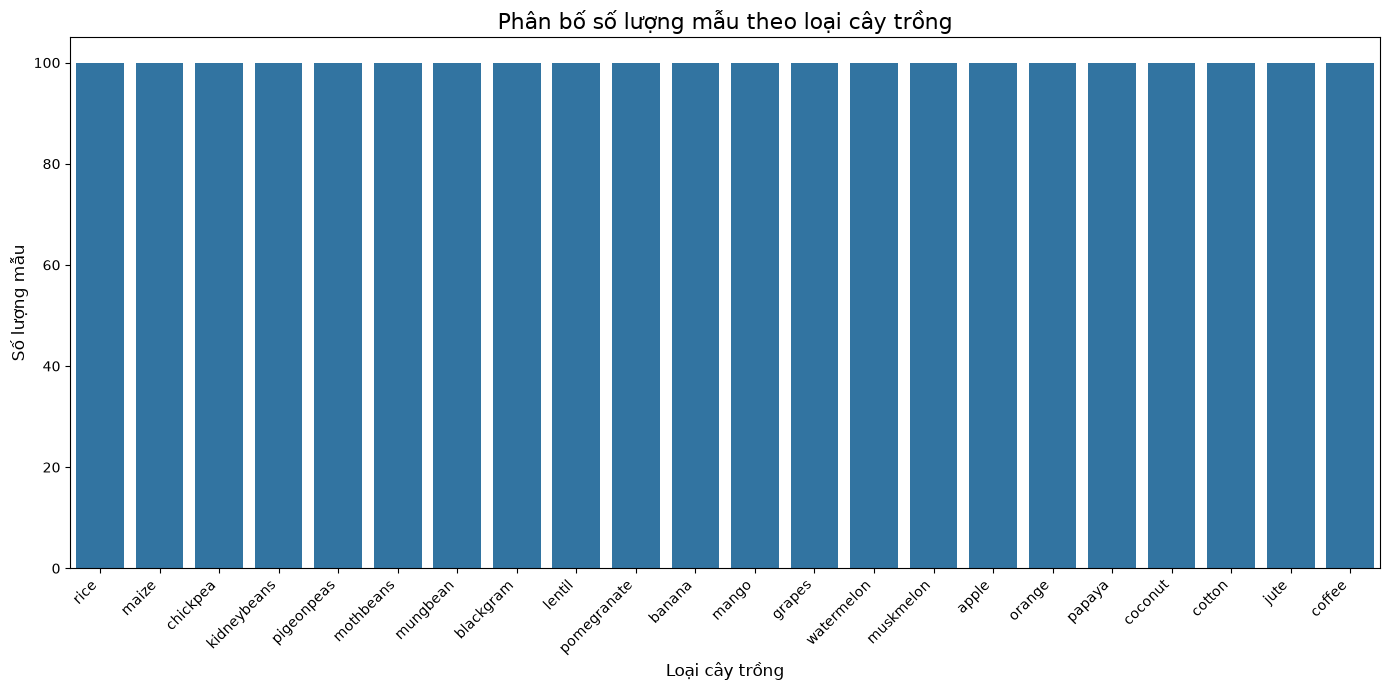

In [ ]:
plt.figure(figsize=(14, 7))

sns.countplot(
    data=df,
    x="label",
    order=df["label"].value_counts().index # sắp xếp theo giá trị
)

plt.title("Phân bố số lượng mẫu theo loại cây trồng", fontsize=16)
plt.xlabel("Loại cây trồng", fontsize=12)
plt.ylabel("Số lượng mẫu", fontsize=12)

plt.xticks(rotation=45, ha="right") # chữ nghiêng và căn lề phải

plt.tight_layout()

plt.savefig(
    "../reports/figures/01_label_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Phân bố các đặc trưng số

Histogram được sử dụng để quan sát sự phân bố của các đặc trưng N, P, K, temperature, humidity, ph và rainfall. Qua đó có thể nhận biết khoảng giá trị phổ biến, mức độ phân tán và những vùng giá trị bất thường.

### Nhận xét

Các đặc trưng có phạm vi và hình dạng phân phối khác nhau. N, P và K có mức độ phân tán khá lớn, trong khi nhiệt độ, độ ẩm và pH tập trung trong những khoảng giá trị tương đối rõ rệt. Lượng mưa có phạm vi biến thiên rộng, do đó cần được kiểm tra thêm bằng Boxplot để xác định các giá trị ngoại lai.

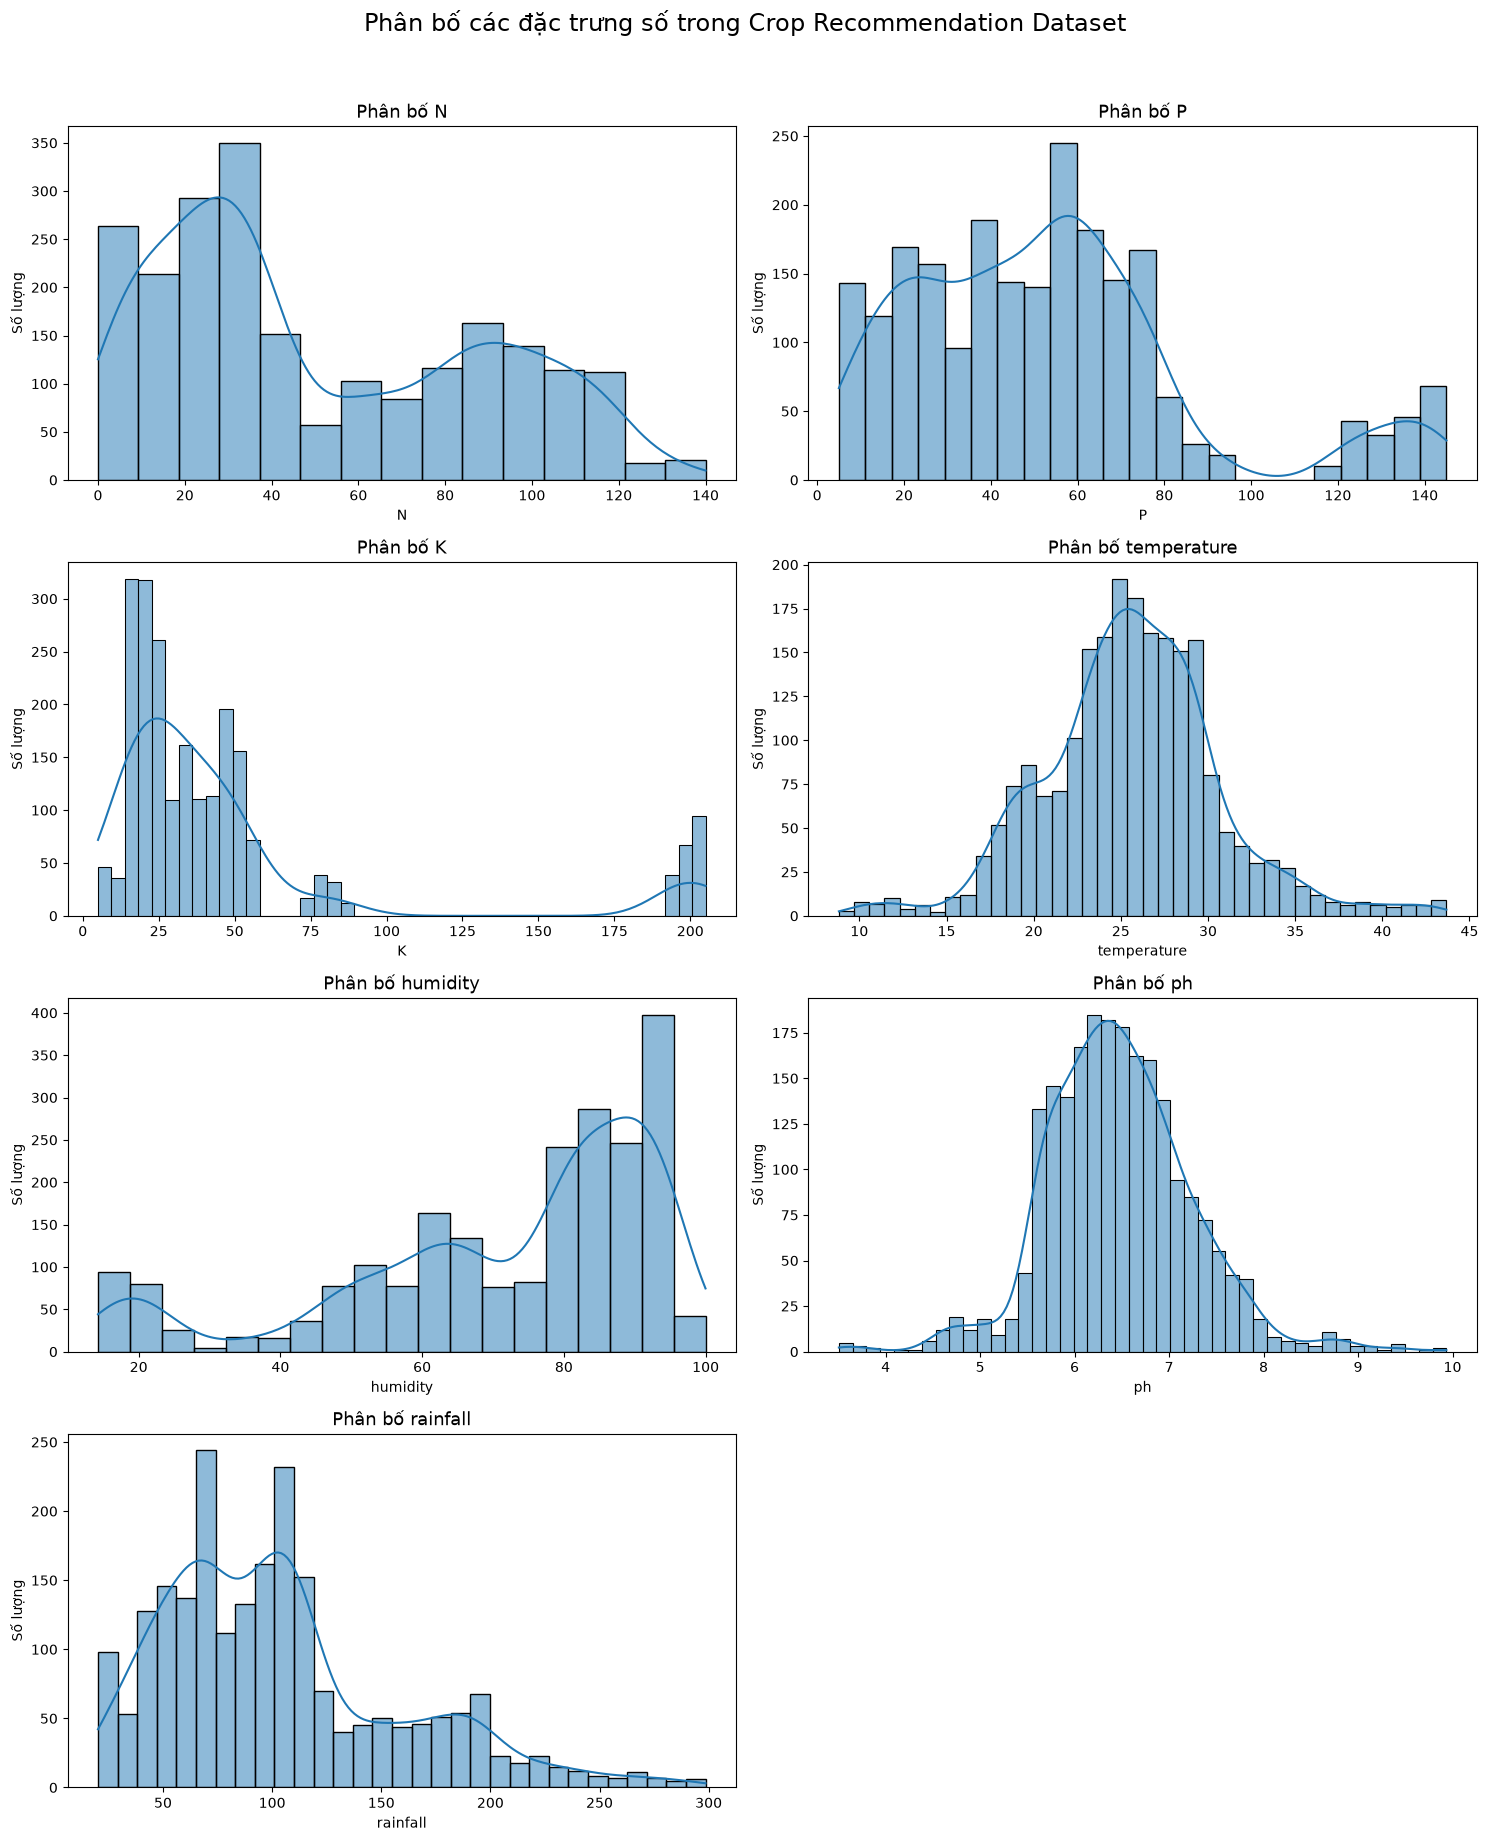

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(15, 18)) # 4 hàng, 2 cột

axes = axes.flatten() # chuyển từ mảng 2 chiều sang mảng 1 chiều

for i, feature in enumerate(numeric_features):
    sns.histplot(
        data=df,
        x=feature,
        kde=True, # đường cong ước lượng mật độ
        ax=axes[i] # chỉ định vẽ vào ô thứ i
    )

    axes[i].set_title(
        f"Phân bố {feature}",
        fontsize=13
    )

    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Số lượng")

axes[-1].remove() # xóa ô cuối cùng vì chỉ có 7 columns

plt.suptitle(
    "Phân bố các đặc trưng số trong Crop Recommendation Dataset",
    fontsize=17,
    y=1.02
)

plt.tight_layout()

plt.savefig(
    "../reports/figures/02_feature_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Phát hiện Outlier bằng Boxplot

Boxplot được sử dụng để kiểm tra sự phân tán của các đặc trưng và phát hiện các giá trị ngoại lai (outliers). Theo quy tắc IQR, các giá trị nằm ngoài khoảng Q1 - 1.5 × IQR và Q3 + 1.5 × IQR được xem là các giá trị ngoại lai cần kiểm tra.

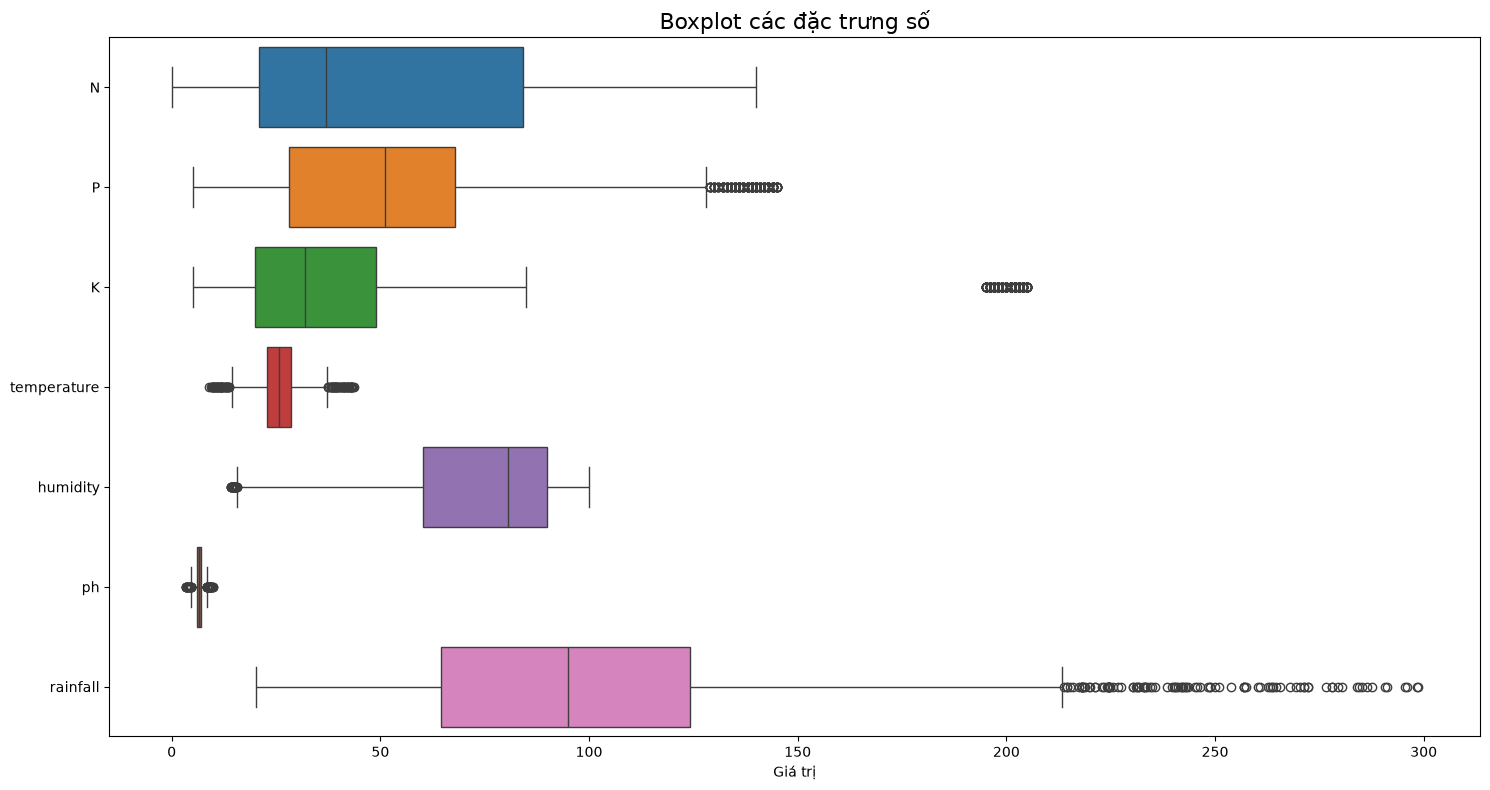

In [ ]:
plt.figure(figsize=(15, 8))

sns.boxplot(
    data=df[numeric_features],
    orient="h" # đặt hướng biểu đồ nằm ngang
)

plt.title(
    "Boxplot các đặc trưng số",
    fontsize=16
)

plt.xlabel("Giá trị")

plt.tight_layout()

plt.savefig(
    "../reports/figures/03_boxplot_features.png",
    dpi=300, # độ phân giải ảnh
    bbox_inches="tight" # bỏ phần viền trắng thừa xung quanh
)

plt.show()

In [87]:
outlier_summary = []

for feature in numeric_features:

    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ]

    outlier_summary.append({
        "Feature": feature,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers)
    })

outlier_df = pd.DataFrame(outlier_summary)

print(outlier_df.to_string(index=False))

    Feature        Q1         Q3       IQR  Lower Bound  Upper Bound  Outlier Count
          N 21.000000  84.250000 63.250000   -73.875000   179.125000              0
          P 28.000000  68.000000 40.000000   -32.000000   128.000000            138
          K 20.000000  49.000000 29.000000   -23.500000    92.500000            200
temperature 22.769375  28.561654  5.792279    14.080956    37.250073             86
   humidity 60.261953  89.948771 29.686818    15.731726   134.478998             30
         ph  5.971693   6.923643  0.951950     4.543768     8.351567             57
   rainfall 64.551686 124.267508 59.715822   -25.022047   213.841241            100


In [91]:
## Giá trị Outlier thực tế
for feature in numeric_features:
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ]

    print(f"\n===== {feature} =====")
    print("Số lượng outlier:", len(outliers))
    print("Giá trị nhỏ nhất:", outliers[feature].min())
    print("Giá trị lớn nhất:", outliers[feature].max())


===== N =====
Số lượng outlier: 0
Giá trị nhỏ nhất: nan
Giá trị lớn nhất: nan

===== P =====
Số lượng outlier: 138
Giá trị nhỏ nhất: 129
Giá trị lớn nhất: 145

===== K =====
Số lượng outlier: 200
Giá trị nhỏ nhất: 195
Giá trị lớn nhất: 205

===== temperature =====
Số lượng outlier: 86
Giá trị nhỏ nhất: 8.825674745
Giá trị lớn nhất: 43.67549305

===== humidity =====
Số lượng outlier: 30
Giá trị nhỏ nhất: 14.25803981
Giá trị lớn nhất: 15.65809214

===== ph =====
Số lượng outlier: 57
Giá trị nhỏ nhất: 3.504752314
Giá trị lớn nhất: 9.93509073

===== rainfall =====
Số lượng outlier: 100
Giá trị nhỏ nhất: 213.9011021
Giá trị lớn nhất: 298.5601175


In [92]:
## Outlier theo từng loại cây
for feature in ["P", "K", "temperature", "humidity", "ph", "rainfall"]:

    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_data = df[
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ]

    print(f"\n===== {feature} =====")
    print(
        outlier_data["label"]
        .value_counts()
        .head(10)
    )


===== P =====
label
apple     70
grapes    68
Name: count, dtype: int64

===== K =====
label
grapes    100
apple     100
Name: count, dtype: int64

===== temperature =====
label
papaya    35
grapes    34
orange    17
Name: count, dtype: int64

===== humidity =====
label
chickpea    30
Name: count, dtype: int64

===== ph =====
label
mothbeans    42
chickpea     13
mango         2
Name: count, dtype: int64

===== rainfall =====
label
rice       68
papaya     17
coconut    15
Name: count, dtype: int64


In [93]:
feature = "ph"

Q1 = df[feature].quantile(0.25)
Q3 = df[feature].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df[feature] < lower_bound) |
    (df[feature] > upper_bound)
]

print("===== PH =====")
print("Số lượng outlier:", len(outliers))
print("Giá trị nhỏ nhất:", outliers[feature].min())
print("Giá trị lớn nhất:", outliers[feature].max())

print("\nOutlier theo từng loại cây:")
print(outliers["label"].value_counts())

===== PH =====
Số lượng outlier: 57
Giá trị nhỏ nhất: 3.504752314
Giá trị lớn nhất: 9.93509073

Outlier theo từng loại cây:
label
mothbeans    42
chickpea     13
mango         2
Name: count, dtype: int64


In [ ]:
feature = "rainfall"

Q1 = df[feature].quantile(0.25) # Sắp xếp nhỏ -> lớn lấy móc ở vị trí 25% 
Q3 = df[feature].quantile(0.75) # Sắp xếp nhỏ -> lớn lấy móc ở vị trí 75% 
IQR = Q3 - Q1 # Dữ liệu lõi

lower_bound = Q1 - 1.5 * IQR   # Giới hạn trên
upper_bound = Q3 + 1.5 * IQR   # Giới hạn dưới

outliers = df[
    (df[feature] < lower_bound) | 
    (df[feature] > upper_bound)
]

print("===== RAINFALL =====")
print("Số lượng outlier:", len(outliers))
print("Giá trị nhỏ nhất:", outliers[feature].min())
print("Giá trị lớn nhất:", outliers[feature].max())

print("\nOutlier theo từng loại cây:")
print(outliers["label"].value_counts())

===== RAINFALL =====
Số lượng outlier: 100
Giá trị nhỏ nhất: 213.9011021
Giá trị lớn nhất: 298.5601175

Outlier theo từng loại cây:
label
rice       68
papaya     17
coconut    15
Name: count, dtype: int64


### Nhận xét Boxplot và Outlier

Kết quả phân tích theo phương pháp IQR cho thấy số lượng outlier giữa các đặc trưng có sự khác biệt. Đặc trưng N không phát hiện outlier, trong khi K có số lượng outlier cao nhất với 200 giá trị, tiếp theo là P với 138 giá trị và rainfall với 100 giá trị. Các đặc trưng temperature, ph và humidity lần lượt có 86, 57 và 30 giá trị được xác định là outlier.

Tuy nhiên, các giá trị outlier không nhất thiết là dữ liệu sai. Trong bài toán dự đoán cây trồng, các giá trị N, P, K, nhiệt độ, độ ẩm, pH và lượng mưa có thể phản ánh những điều kiện đất và khí hậu đặc biệt. Vì vậy, cần kiểm tra và đánh giá thêm trước khi quyết định loại bỏ hoặc thay thế các giá trị này trong bước tiền xử lý.

In [ ]:
print("Số lượng Outlier của từng đặc trưng:")

print(
    outlier_df[
        ["Feature", "Outlier Count"] # Lấy 2 cột chính để xét
    ].to_string(index=False)
)

Số lượng Outlier của từng đặc trưng:
    Feature  Outlier Count
          N              0
          P            138
          K            200
temperature             86
   humidity             30
         ph             57
   rainfall            100


### Nhận xét

Boxplot cho phép xác định các giá trị ngoại lai của từng đặc trưng. Số lượng outlier được tính bằng phương pháp IQR và sẽ được sử dụng để đánh giá xem đặc trưng nào cần được kiểm tra trong bước tiền xử lý dữ liệu.

In [75]:
print("Số lượng Outlier của từng đặc trưng:")

print(
    outlier_df[
        ["Feature", "Outlier Count"]
    ].to_string(index=False)
)

Số lượng Outlier của từng đặc trưng:
    Feature  Outlier Count
          N              0
          P            138
          K            200
temperature             86
   humidity             30
         ph             57
   rainfall            100


## Ma trận tương quan giữa các đặc trưng

Ma trận tương quan được sử dụng để đánh giá mức độ quan hệ tuyến tính giữa các đặc trưng số. Hệ số tương quan nằm trong khoảng từ -1 đến 1; giá trị gần 1 thể hiện tương quan thuận mạnh, gần -1 thể hiện tương quan nghịch mạnh và gần 0 thể hiện tương quan tuyến tính yếu.

In [84]:
correlation_matrix = df[numeric_features].corr()

print(
    correlation_matrix.round(3)
)

                 N      P      K  temperature  humidity     ph  rainfall
N            1.000 -0.231 -0.141        0.027     0.191  0.097     0.059
P           -0.231  1.000  0.736       -0.128    -0.119 -0.138    -0.064
K           -0.141  0.736  1.000       -0.160     0.191 -0.170    -0.053
temperature  0.027 -0.128 -0.160        1.000     0.205 -0.018    -0.030
humidity     0.191 -0.119  0.191        0.205     1.000 -0.008     0.094
ph           0.097 -0.138 -0.170       -0.018    -0.008  1.000    -0.109
rainfall     0.059 -0.064 -0.053       -0.030     0.094 -0.109     1.000


### Nhận xét

Ma trận tương quan cho thấy mức độ liên hệ giữa các đặc trưng không giống nhau. Một số cặp biến có tương quan thuận hoặc nghịch ở các mức độ khác nhau, trong khi một số cặp có tương quan thấp, cho thấy các đặc trưng cung cấp những thông tin tương đối khác biệt cho bài toán dự đoán loại cây trồng.

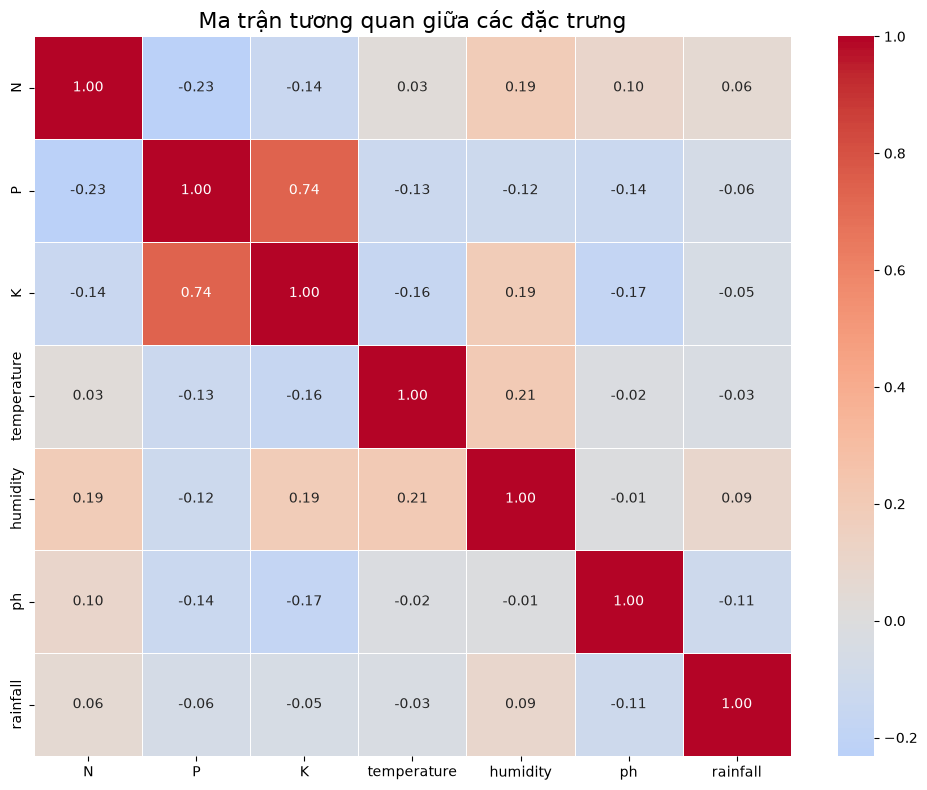

In [83]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title(
    "Ma trận tương quan giữa các đặc trưng",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "../reports/figures/04_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [82]:
corr_pairs = correlation_matrix.where(
    ~np.eye(
        correlation_matrix.shape[0],
        dtype=bool
    )
).stack()

corr_pairs = corr_pairs.reindex(
    corr_pairs.abs().sort_values(
        ascending=False
    ).index
)

print("Các cặp đặc trưng có tương quan mạnh nhất:")

print(
    corr_pairs.head(10).round(3)
)

Các cặp đặc trưng có tương quan mạnh nhất:
P            K              0.736
K            P              0.736
P            N             -0.231
N            P             -0.231
temperature  humidity       0.205
humidity     temperature    0.205
K            humidity       0.191
humidity     K              0.191
             N              0.191
N            humidity       0.191
dtype: float64


## Tổng hợp chất lượng dữ liệu

Sau khi thực hiện EDA, tiến hành tổng hợp các kết quả về kích thước dữ liệu, kiểu dữ liệu, giá trị thiếu, dữ liệu trùng lặp, phân bố nhãn và outlier. Kết quả này được sử dụng để bàn giao cho Thành viên 3 thực hiện bước tiền xử lý dữ liệu.

Vấn đề: Đường chéo của ma trận luôn bằng 1.0 (vì một biến luôn tương quan tuyệt đối với chính nó) và phần tam giác trên/dưới bị đối xứng (đều có cùng cặp biến).

Mục đích: Loại bỏ đường chéo đó và xếp hạng các cặp tương quan.

## Kết luận EDA

Dataset Crop Recommendation gồm 2.200 mẫu dữ liệu với 8 cột, bao gồm 7 đặc trưng đầu vào là N, P, K, temperature, humidity, ph và rainfall, cùng với biến mục tiêu label.

Kết quả kiểm tra cho thấy dataset không có giá trị thiếu và không có dòng dữ liệu trùng lặp. Biến mục tiêu gồm 22 loại cây trồng và mỗi loại có đúng 100 mẫu, do đó dữ liệu được phân bố đồng đều giữa các lớp và không có vấn đề mất cân bằng nhãn.

Histogram được sử dụng để quan sát phân bố của các đặc trưng. Boxplot được sử dụng để phát hiện các giá trị ngoại lai theo quy tắc IQR. Các outlier cần được kiểm tra trước khi quyết định xử lý, vì chúng có thể là những giá trị hợp lệ đại diện cho điều kiện đất hoặc khí hậu đặc biệt.

Correlation Heatmap giúp xác định mức độ tương quan giữa các đặc trưng. Các kết quả EDA là cơ sở để Thành viên 3 lựa chọn phương pháp tiền xử lý phù hợp trước khi xây dựng mô hình phân lớp và gom cụm.

In [ ]:
print("========== TỔNG HỢP CHẤT LƯỢNG DỮ LIỆU ==========")

print("\n1. Kích thước dataset:")
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])

print("\n2. Missing values:")
print(df.isnull().sum())  

print("\n3. Duplicate:")
print(df.duplicated().sum())

print("\n4. Số lớp label:")
print(df["label"].nunique())

print("\n5. Số mẫu mỗi lớp:")
print(df["label"].value_counts())

print("\n6. Outlier:")
print(
    outlier_df[
        ["Feature", "Outlier Count"]
    ].to_string(index=False)
)

========== TỔNG HỢP CHẤT LƯỢNG DỮ LIỆU ==========

1. Kích thước dataset:
Số dòng: 2200
Số cột: 8

2. Missing values:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

3. Duplicate:
0

4. Số lớp label:
22

5. Số mẫu mỗi lớp:
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64

6. Outlier:
    Feature  Outlier Count
          N              0
          P            138
          K            200
temperature             86
   humidity             30
         ph             57
   rainfall            